In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimize import grid_search, strategy_compare
from app import BacktestDCA
from ploter import ploter

In [2]:
SEARCH_SPACE = {
    "minimum_profit": [1.1, 1.5, 2.0],
    "cooldown_long": [30, 60, 90],
    "cooldown_short": [7, 14, 30],
}

In [3]:
STRATEGIES = {
    "BuyHold": {"classic_dca": True},
    "Default": {},
    "NoConfirm": {"manual_sell_fraction": 0.5, "minimum_profit": 2.0},
    "Experiment": {"minimum_profit": 1.1, "cooldown_long": 30.0, "cooldown_short": 7.0},
}

In [4]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True).dropna(axis=1)
df_prices

,BTC,ETH,XRP,USDT,BCH,LTC,EOS,BNB,BSV,XLM,...,MKR,ONT,DOGE,VET,BAT,OMG,SNX,ZRX,ICX,QTUM
Date,,,,,,,,,,,,,,,,,,,,,
2020-02-13,10214.379883,268.099243,0.326706,0.998579,474.317993,80.403427,5.341575,25.440100,359.041138,0.082655,...,625.763184,1.021036,0.003026,0.008026,0.295389,1.280141,0.932967,0.320865,0.394342,2.842507
2020-02-14,10312.116211,284.217499,0.334822,1.000114,491.160645,82.990349,5.361947,26.296959,360.390015,0.085796,...,638.993713,1.071109,0.003130,0.008323,0.311020,1.370907,0.992797,0.345264,0.400229,3.015611
2020-02-15,9889.424805,264.728577,0.306236,0.999128,437.664948,76.513245,4.743118,24.149651,310.077820,0.079246,...,607.280212,0.957589,0.002920,0.007440,0.280342,1.289413,0.949770,0.317226,0.360399,2.677241
2020-02-16,9934.433594,259.894714,0.295034,0.999272,415.940643,75.152588,4.412250,23.466389,285.867523,0.075079,...,634.711975,0.909603,0.002774,0.007133,0.264260,1.190897,0.945258,0.299002,0.348740,2.511193
2020-02-17,9690.142578,266.363434,0.286572,0.998474,409.344574,73.251305,4.346360,23.551378,309.441620,0.071851,...,614.943604,0.878514,0.002712,0.006756,0.266563,1.169630,1.011205,0.291352,0.344687,2.499368
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-03-31,68233.312500,2104.708252,1.340259,0.999024,466.334564,53.917908,0.075516,617.049194,13.852106,0.167265,...,1740.242554,0.083272,0.092208,0.006763,0.096228,0.054769,0.287147,0.103136,0.034007,0.887649
2026-04-01,68078.554688,2138.737061,1.347766,0.999800,454.311554,53.805855,0.078632,610.622986,14.003111,0.169253,...,1785.234497,0.112436,0.092191,0.006885,0.099325,0.055448,0.281543,0.104537,0.035458,0.930321
2026-04-02,66888.570312,2056.852539,1.318691,0.999892,444.056213,52.260174,0.076542,583.136841,14.614312,0.163015,...,1750.205811,0.108114,0.090374,0.006740,0.094341,0.053399,0.278585,0.102121,0.035270,0.879604


# SEARCH

In [ ]:
history_search = grid_search(
    prices=df_prices, 
    param_grid=SEARCH_SPACE, 
    n_boot=20,
    sample_size=10,
    sequence_length=365 * 4,
    )

  0%|          | 0/27 [00:00<?, ?it/s]

100%|██████████| 27/27 [04:21<00:00,  9.67s/it]


In [ ]:
history_search

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC,iteration
0,minimum_profit=1.1_cooldown_long=30_cooldown_s...,XLM,2029,1192,693,997,1886,13,0.127732,9,-52,-337,381.000000,-22,1
1,minimum_profit=1.1_cooldown_long=30_cooldown_s...,BSV,1970,1097,703,1308,1800,27,28.283564,9,-32,-391,0.000000,20,1
2,minimum_profit=1.1_cooldown_long=30_cooldown_s...,BTC,1782,1033,2359,1014,3393,66,29353.341895,6,-60,-785,70.000000,20,1
3,minimum_profit=1.1_cooldown_long=30_cooldown_s...,XRP,1782,3743,1111,463,4855,77,1.238966,9,-32,-562,82.500000,24,1
4,minimum_profit=1.1_cooldown_long=30_cooldown_s...,ONT,1980,1387,937,1010,2324,17,0.241429,8,-56,-677,149.000000,-17,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5395,minimum_profit=2.0_cooldown_long=90_cooldown_s...,VET,1782,1962,761,868,2723,37,0.026208,2,-35,-921,134.000000,37,20
5396,minimum_profit=2.0_cooldown_long=90_cooldown_s...,BAT,1782,0,920,1782,920,33,0.195670,0,-61,-1444,141.666667,-12,20
5397,minimum_profit=2.0_cooldown_long=90_cooldown_s...,DASH,2227,54,1315,2205,1370,23,49.368369,10,-59,-839,117.000000,-29,20
5398,minimum_profit=2.0_cooldown_long=90_cooldown_s...,DASH,1782,2048,1761,910,3810,25,31.970481,1,-66,-1815,11.500000,-21,20


In [ ]:
search_res = history_search.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    MDD_usd=("MDD_usd", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_meadian=("Total_value", "median"),
    Total_value_25=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_75=("Total_value", lambda s: np.percentile(s, 75)),
)

search_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,MDD_usd,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_meadian,Total_value_25,Total_value_75
strategy,,,,,,,,,,
minimum_profit=1.1_cooldown_long=60_cooldown_short=14,21.70,-45.48,-1236.51,1477.26,1327.91,1901.08,2805.68,2369.00,1875.00,3217.50
minimum_profit=1.1_cooldown_long=30_cooldown_short=7,20.27,-42.98,-901.60,1220.53,1526.60,1918.20,2747.64,2582.00,1906.25,3338.25
minimum_profit=1.5_cooldown_long=60_cooldown_short=14,17.71,-46.84,-1191.27,1508.58,1182.04,1930.01,2691.07,2387.50,1781.00,3223.75
minimum_profit=1.5_cooldown_long=90_cooldown_short=7,16.80,-47.11,-1220.94,1471.91,1212.00,1940.49,2684.36,2508.50,1780.25,3131.25
minimum_profit=1.5_cooldown_long=30_cooldown_short=14,16.11,-46.57,-1077.38,1327.81,1376.01,1937.90,2704.27,2365.50,1780.75,3086.25
minimum_profit=2.0_cooldown_long=30_cooldown_short=7,15.75,-48.47,-1224.22,1589.60,1137.67,1920.38,2727.58,2626.50,1749.00,3610.25
minimum_profit=2.0_cooldown_long=90_cooldown_short=7,15.71,-48.67,-1447.15,1784.64,934.95,1917.73,2719.89,2498.50,1749.75,3554.50
minimum_profit=1.5_cooldown_long=30_cooldown_short=7,13.49,-45.08,-1008.28,1391.06,1758.31,1928.47,3149.84,2930.50,2042.25,3663.75
minimum_profit=2.0_cooldown_long=30_cooldown_short=14,13.44,-48.41,-1218.37,1541.88,1135.93,1936.71,2678.11,2247.50,1546.00,3481.75


# COMPARE

In [22]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 4,
)

100%|██████████| 4/4 [03:11<00:00, 47.79s/it]


In [23]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC,iteration
0,BuyHold,DOGE,1782,0,11314,1782,11314,98,0.027929,0,-91,-30320,0.000000,287,1
1,BuyHold,VET,1782,0,1522,1782,1522,26,0.027119,0,-72,-3368,132.666667,-21,1
2,BuyHold,BCH,1782,0,3714,1782,3714,48,213.594823,0,-54,-2776,104.500000,-2,1
3,BuyHold,BTC,1782,0,5011,1782,5011,53,34669.801208,0,-40,-718,114.000000,3,1
4,BuyHold,BTC,1782,0,5168,1782,5168,53,34023.728360,0,-43,-746,166.000000,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,Experiment,BAT,1831,871,827,1103,1698,13,0.206662,2,-50,-826,22.461538,-20,100
3996,Experiment,OMG,2237,1442,477,1087,1920,11,0.253207,14,-52,-434,0.000000,-11,100
3997,Experiment,NEO,2029,1423,982,821,2405,33,11.593339,11,-58,-813,117.000000,-2,100
3998,Experiment,SNX,2138,1522,359,847,1882,36,0.835877,13,-52,-878,134.500000,-7,100


In [29]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    MDD_usd=("MDD_usd", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_meadian=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 5)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 95)),
)

compare_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,MDD_usd,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_meadian,Total_value_low,Total_value_high
strategy,,,,,,,,,,
Experiment,15.90,-43.13,-885.58,1237.37,1449.53,1929.80,2687.39,2415.50,1465.70,4629.15
Default,12.82,-45.93,-1139.46,1510.84,1386.54,1927.31,2897.85,2470.00,1437.65,5011.80
NoConfirm,9.73,-46.63,-1083.14,1305.45,1374.81,1943.61,2680.58,2578.00,971.00,4834.55
BuyHold,-6.11,-60.02,-2060.23,2391.16,0.00,1782.00,2391.16,1781.00,609.75,5632.20


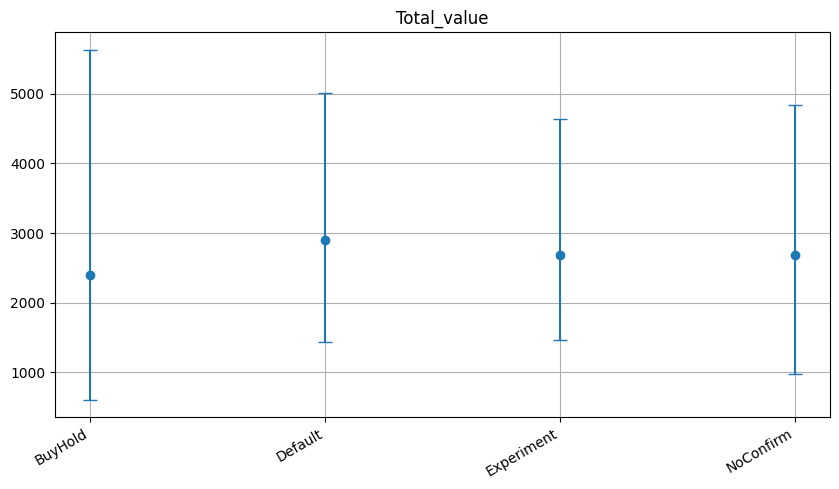

In [31]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

means = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    means.index,
    means.values,
    yerr=[means - low, high - means],
    fmt="o",
    capsize=5,
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()